# Coding Project 2: Credit Analytics

**Names of all group members: Shangeeth Poobalasingam and Ding Weifeng **


---

All code below is only suggestive and you may as well use different approaches.
Make sure that all requested quantities are printed or shown in tables/plots in the executed notebook.
A concise *Project Report* is required at the end of the notebook (see the last cells).

In [1]:
# Exercise 1.
import numpy as np
np.random.seed(0)  # for reproducibility

# simulate explanatory variables x (the age and monthly income are assumed here to follow a continuous uniform distribution)
m = 20000
n = 10000

age = np.random.uniform(18, 80, m + n)
income = np.random.uniform(1, 15, m + n)              # in CHF 1000
self_employed = np.random.binomial(1, 0.1, m + n)     # 1 = self-employed (prob 10%), 0 = salaried

X = np.column_stack((age, income, self_employed))
X_train = X[:m]
X_test = X[m:]


# a) calculate and print the empirical means and standard deviations over the training data (i = 1, ..., m)
means = X_train.mean(axis=0)
stds = X_train.std(axis=0)

names = ["age", "income", "self-employed"]
for j in range(3):
    print(f"{names[j]}: mean = {means[j]:.4f}, std = {stds[j]:.4f}")


# b) Can you come up with a few (2 or 3) additional features that may be relevant?
# (you don't have to implement those of course, just write down your answer in text)
#
# - debts the person already has (other loans, credit cards), e.g. as debt-to-income ratio
# - past credit history, e.g. earlier missed payments or a credit score
# - details of the loan and the job: loan amount and duration, how long they have had their job, owning a house or not
#


age: mean = 48.7427, std = 18.0074
income: mean = 7.9865, std = 4.0308
self-employed: mean = 0.1017, std = 0.3023


In [2]:
# Exercise 2.
# Building the datasets:

sigmoid = lambda x: 1. / (1. + np.exp(-x))

# build the first dataset
xi = np.random.uniform(0, 1, m + n)

p1 = sigmoid(13.3 - 0.33 * age + 3.5 * income - 3 * self_employed)
y1 = (xi <= p1).astype(int)

# build the second dataset
too_young_or_old = (age < 25) | (age > 75)
p2 = sigmoid(5 - 10 * too_young_or_old + 1.1 * income - self_employed)
y2 = (xi <= p2).astype(int)

y1_train = y1[:m]
y1_test = y1[m:]
y2_train = y2[:m]
y2_test = y2[m:]

print("share of good borrowers in data set 1:", y1.mean())
print("share of good borrowers in data set 2:", y2.mean())



share of good borrowers in data set 1: 0.9517666666666666
share of good borrowers in data set 2: 0.9492333333333334


In [3]:
# Exercise 2. a)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss
# "model = LogisticRegression().fit(X_data, Y_data)" fits a model
# "pred_X = model.predict_proba(X)" evaluates the model
# (note that it outputs both P(Y=0|X) and P(Y=1|X))
# "log_loss(Y, pred_X)" evaluates the negative conditional log likelihood (also called cross-entropy loss)

# Fit the models on both datasets
log_model1 = LogisticRegression().fit(X_train, y1_train)
log_model2 = LogisticRegression().fit(X_train, y2_train)

# Calculate and print the cross-entropy loss on both datasets for train and test
p_log1_train = log_model1.predict_proba(X_train)[:, 1]
p_log1_test = log_model1.predict_proba(X_test)[:, 1]
p_log2_train = log_model2.predict_proba(X_train)[:, 1]
p_log2_test = log_model2.predict_proba(X_test)[:, 1]

print(f"Logistic regression, data set 1: train loss = {log_loss(y1_train, p_log1_train):.4f}, test loss = {log_loss(y1_test, p_log1_test):.4f}")
print(f"Logistic regression, data set 2: train loss = {log_loss(y2_train, p_log2_train):.4f}, test loss = {log_loss(y2_test, p_log2_test):.4f}")



Logistic regression, data set 1: train loss = 0.0297, test loss = 0.0349
Logistic regression, data set 2: train loss = 0.1535, test loss = 0.1486


In [4]:
# Exercise 2. b)
# Calculate normalized data
# (as in the assignment: divide by the empirical standard deviations of the TRAINING data,
#  for both training and test data)
sigma = X_train.std(axis=0)

X_train_norm = X_train / sigma
X_test_norm = X_test / sigma
print("sigma =", sigma)



sigma = [18.00743828  4.03080286  0.30225339]


In [5]:
# Exercise 2.b) (i) and (ii)
from sklearn.svm import SVC
# "model = SVC(kernel='rbf', gamma=GAMMA, C=C, probability=True)" creates
# a model with kernel exp(-GAMMA \|x-x'\|_2^2) and regularization parameter C (note the relation between C and the parameter lambda from the lecture).
# "probability=True" enables the option "model.predict_proba(X)" to predict probabilities from the regression function \hat{f}^{svm}.
# "model.fit(X, Y)" optimizes the model parameters (using hinge loss)

# Fit the models for both datasets (this can take up to 60 seconds with SVC)
# Note: "model.fit(...)" modifies the model object in place, so use a separate model object
# for each dataset if you want to keep both fitted models.

# kernel exp(-1/10 ||x - x'||^2) -> gamma = 0.1, and C = 1/(2 * lambda * m) = 0.2
svm_model1 = SVC(kernel='rbf', gamma=0.1, C=0.2, probability=True)
svm_model1.fit(X_train_norm, y1_train)

svm_model2 = SVC(kernel='rbf', gamma=0.1, C=0.2, probability=True)
svm_model2.fit(X_train_norm, y2_train)

print("SVMs are fitted")



/home/shangeeth/miniconda3/envs/mlfi/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/shangeeth/miniconda3/envs/mlfi/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVMs are fitted


In [6]:
# Exercise 2.b (iii)
# "model.predict_proba(X)" predicts probabilities from features (note that it outputs both P(Y=0|X) and P(Y=1|X))
p_svm1_train = svm_model1.predict_proba(X_train_norm)[:, 1]
p_svm1_test = svm_model1.predict_proba(X_test_norm)[:, 1]
p_svm2_train = svm_model2.predict_proba(X_train_norm)[:, 1]
p_svm2_test = svm_model2.predict_proba(X_test_norm)[:, 1]

# Calculate and print the cross-entropy loss on both normalized datasets for train and test
print(f"SVM, data set 1: train loss = {log_loss(y1_train, p_svm1_train):.4f}, test loss = {log_loss(y1_test, p_svm1_test):.4f}")
print(f"SVM, data set 2: train loss = {log_loss(y2_train, p_svm2_train):.4f}, test loss = {log_loss(y2_test, p_svm2_test):.4f}")


SVM, data set 1: train loss = 0.0319, test loss = 0.0388
SVM, data set 2: train loss = 0.0711, test loss = 0.0671


In [ ]:
# Exercise 2.b (iv)
#Would the results change using standardized data instead of normalized data? No need to run any code here, only explain your reasoning.
#
# No. z~ = x~ - mu/sigma is just the same shift for every point, and the RBF kernel exp(-1/10 ||x - x'||^2) is shift invariant (it only depends on x - x'), so the kernel matrix stays exactly the same.
# So the SVM problem, the f_svm values, the Platt scaling and the probabilities and cross-entropy losses are all the same (up to the random split probability=True uses internally); with a kernel that isn't shift invariant, e.g. a polynomial one, this could change.

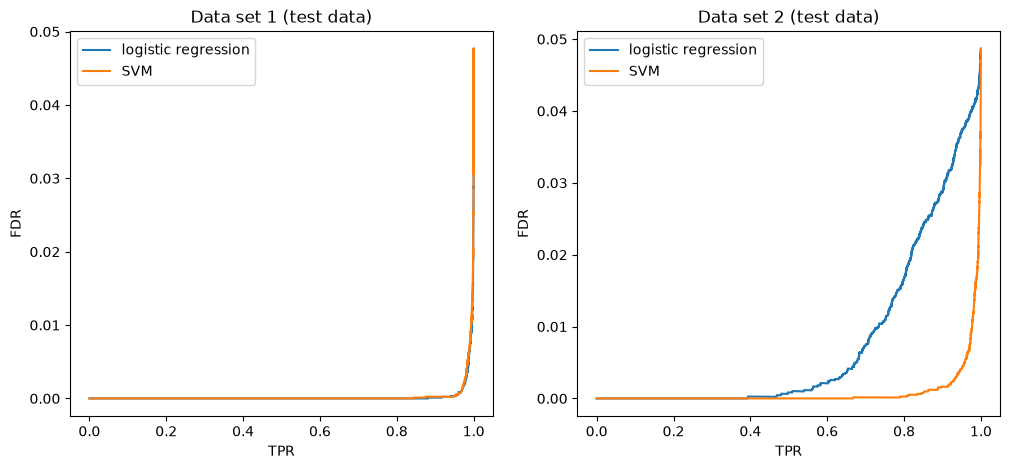

AUC data set 1: logistic regression = 0.00021, SVM = 0.00025
AUC data set 2: logistic regression = 0.00777, SVM = 0.00085


In [8]:
# Exercise 2.c
# Plot the FDR/TPR-curves with the TPR on the horizontal axis and the FDR on the vertical axis,
# and compute the AUC of each plotted curve on the test data.
import matplotlib.pyplot as plt
# Thresholds c: you may use all distinct predicted probabilities (this gives the exact curve), or a grid of
# values in [0, 1]. A uniform grid such as np.linspace(0, 1, 100) can be too coarse when many predicted
# probabilities are very close to 1. Check that your curve covers TPR values from (close to) 0 to 1.

# To approximately calculate the AUC, it is fine to simply use Riemann sums.
# This means, if you have N (a_i, b_i) pairs for the curves, ordered such that a_1 <= a_2 <= ... <= a_N,
# then you may simply use the sum
# sum_{i=1}^{N-1} (b_i + b_{i+1})/2 * (a_{i+1}-a_i)
# as the approximation of the integral (or AUC)


# first data set & logistic regression:
# (the code should be reusable for all cases, only exchanging datasets and predicted probabilities depending on the model)
def fdr_tpr_curve(y, p):
    # we give a loan ("positive") if p >= c, and use all distinct predicted probabilities as c
    thresholds = np.unique(p)

    # Calculate positives (only depending on the dataset)
    P = np.sum(y == 1)

    # Calculate true positives for all threshold values
    TP = np.array([np.sum((p >= c) & (y == 1)) for c in thresholds])

    # Calculate false positives for all threshold values
    FP = np.array([np.sum((p >= c) & (y == 0)) for c in thresholds])

    # Calculate FDR and TPR rate (points on the FDR/TPR curve) and the AUC
    TPR = TP / P
    FDR = FP / (TP + FP)
    # point where nobody gets a loan: TPR = 0 and FDR = 0/0, here we use FDR = 0
    TPR = np.append(TPR, 0)
    FDR = np.append(FDR, 0)
    # order the points by TPR and use the Riemann sum from above
    order = np.argsort(TPR)
    TPR = TPR[order]
    FDR = FDR[order]
    AUC = np.sum((FDR[1:] + FDR[:-1]) / 2 * (TPR[1:] - TPR[:-1]))
    return TPR, FDR, AUC

TPR_log1, FDR_log1, AUC_log1 = fdr_tpr_curve(y1_test, p_log1_test)

# second data set & logistic regression:
TPR_log2, FDR_log2, AUC_log2 = fdr_tpr_curve(y2_test, p_log2_test)

# first data set and SVM:
TPR_svm1, FDR_svm1, AUC_svm1 = fdr_tpr_curve(y1_test, p_svm1_test)

# second data set and SVM:
TPR_svm2, FDR_svm2, AUC_svm2 = fdr_tpr_curve(y2_test, p_svm2_test)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(TPR_log1, FDR_log1, label="logistic regression")
plt.plot(TPR_svm1, FDR_svm1, label="SVM")
plt.xlabel("TPR")
plt.ylabel("FDR")
plt.title("Data set 1 (test data)")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(TPR_log2, FDR_log2, label="logistic regression")
plt.plot(TPR_svm2, FDR_svm2, label="SVM")
plt.xlabel("TPR")
plt.ylabel("FDR")
plt.title("Data set 2 (test data)")
plt.legend()

plt.show()

# Print the AUC values.
print(f"AUC data set 1: logistic regression = {AUC_log1:.5f}, SVM = {AUC_svm1:.5f}")
print(f"AUC data set 2: logistic regression = {AUC_log2:.5f}, SVM = {AUC_svm2:.5f}")
# Briefly explain (in a Markdown cell or comments) how you construct the curves, interpret what
# the AUC means in this setting, and compare the two models on both data sets.
#
# How we build the curves: for every threshold c (all distinct predicted probabilities on the test set)
# we give a loan to everybody with p_hat >= c. Then TPR = TP / P is the share of good borrowers that get a loan
# and FDR = FP / (TP + FP) is the share of the given loans that go bad. For a high c only a few people get a loan
# (TPR close to 0), for the smallest c everybody gets one (TPR = 1 and FDR = share of bad borrowers, about 4.9%).
# If nobody gets a loan FDR is 0/0, there we use FDR = 0. The points are sorted by TPR for the AUC.
#
# Meaning of the AUC: it is the average FDR over all TPR levels, so roughly "how many of our loans go bad on average"
# if we look at all possible amounts of lending. Here small is good (flat curve close to 0). A perfect ranking of the
# borrowers gives AUC = 0, random lending gives FDR = 4.9% everywhere, so AUC around 0.049.
# The AUC only depends on the ranking of the borrowers, not on whether the probabilities themselves are correct.
#
# Comparison:
# - data set 1: both curves stay at 0 until TPR is about 0.9 and both AUCs are tiny (0.00021 vs 0.00025).
#   The logistic regression is a little better, which makes sense because p1 is exactly a logistic model.
# - data set 2: the SVM is much better (AUC 0.00085 vs 0.00777). The logistic regression curve already goes up
#   from TPR around 0.4, the SVM curve only near TPR 0.9. The logistic regression is linear in age, so it cannot
#   see that young (< 25) and old (> 75) people are much riskier, the RBF kernel SVM can learn this.

share of loans paid back over all scenarios: 0.949993618


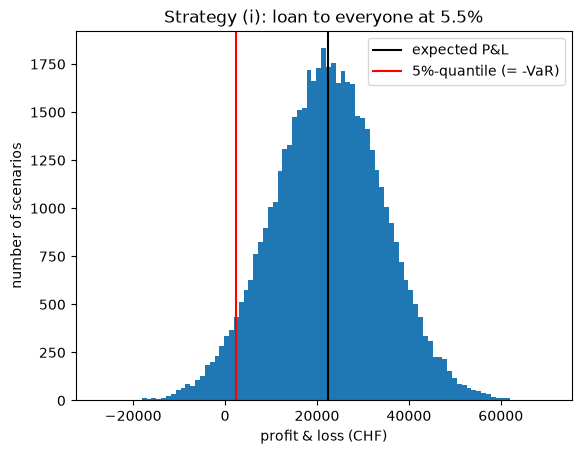

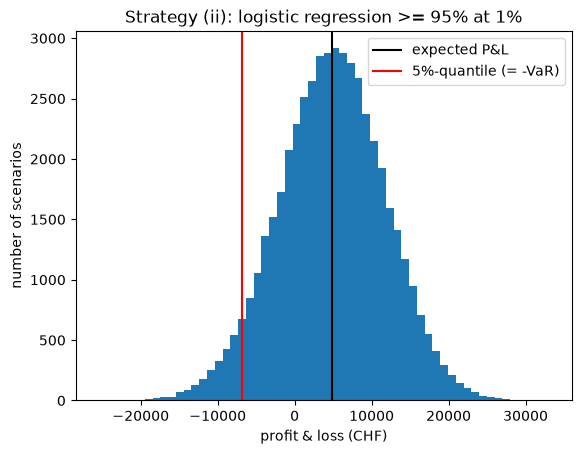

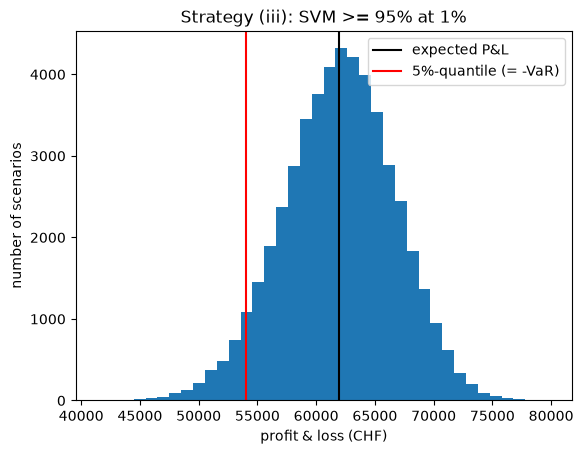

Strategy (i):   10000 loans, expected P&L = 22433 CHF, 95%-VaR = -2455 CHF
Strategy (ii):  6992 loans, expected P&L = 4826 CHF, 95%-VaR = 6840 CHF
Strategy (iii): 8841 loans, expected P&L = 61951 CHF, 95%-VaR = -54070 CHF


In [9]:
# Exercise 3.

# Set model parameters and define matrix D
# (D has n x 50000 = 5*10^8 entries: a float64 array of uniforms of this size needs about 4 GB of memory.
#  If your machine runs out of memory, consider generating D in blocks of columns and/or storing it as booleans.)
K = 50000
loan = 1000                 # every loan is CHF 1000
p2_test = p2[m:]            # true repayment probabilities of the test applicants

# D is stored as booleans and filled in blocks of 5000 scenarios
D = np.zeros((n, K), dtype=bool)
block = 5000
for k in range(0, K, block):
    xi_block = np.random.uniform(0, 1, (n, block))
    D[:, k:k + block] = xi_block <= p2_test[:, None]

print("share of loans paid back over all scenarios:", D.mean())

def profit_and_loss(funded, rate):
    # funded = True/False for every test applicant
    # repaid loans give loan * rate profit, delinquent loans lose the whole loan
    repaid = D[funded].sum(axis=0)          # number of repaid loans in each scenario
    defaulted = funded.sum() - repaid
    return repaid * loan * rate - defaulted * loan

def plot_pnl(pnl, rate, title):
    # the P&L only changes in steps of loan * (1 + rate) (one loan more or less paid back),
    # so we use one bin for every possible value (otherwise the histogram has empty gaps)
    step = loan * (1 + rate)
    bins = np.arange(pnl.min() - step / 2, pnl.max() + step, step)
    plt.figure()
    plt.hist(pnl, bins=bins)
    plt.axvline(pnl.mean(), color="black", label="expected P&L")
    plt.axvline(np.quantile(pnl, 0.05), color="red", label="5%-quantile (= -VaR)")
    plt.xlabel("profit & loss (CHF)")
    plt.ylabel("number of scenarios")
    plt.title(title)
    plt.legend()
    plt.show()


# Strategy (i):
# Define Portfolio and possible outcomes for this portfolio using matrix D
funded_1 = np.ones(n, dtype=bool)           # everybody gets a loan
pnl_1 = profit_and_loss(funded_1, 0.055)

# Plot histogram of profits and losses
plot_pnl(pnl_1, 0.055, "Strategy (i): loan to everyone at 5.5%")

# Calculate expected profit and losses and 95%-VaR
mean_1 = pnl_1.mean()
VaR_1 = -np.quantile(pnl_1, 0.05)


# Strategy (ii):
# Define Portfolio and possible outcomes using the matrix D and the predicted repayment probabilities from the logistic regression model
funded_2 = p_log2_test >= 0.95
pnl_2 = profit_and_loss(funded_2, 0.01)

# Plot histogram of profits and losses
plot_pnl(pnl_2, 0.01, "Strategy (ii): logistic regression >= 95% at 1%")

# Calculate expected profit and losses and 95%-VaR
mean_2 = pnl_2.mean()
VaR_2 = -np.quantile(pnl_2, 0.05)


# Strategy (iii):
# Define Portfolio and possible outcomes using the matrix D and the predicted repayment probabilities from the SVM model
# (evaluated on the normalized test features x~_i, see the assignment)
funded_3 = p_svm2_test >= 0.95
pnl_3 = profit_and_loss(funded_3, 0.01)

# Plot histogram of profits & losses (which is simply the performance of each strategy in scenario k, i.e. a profit if positive or a loss if negative)
plot_pnl(pnl_3, 0.01, "Strategy (iii): SVM >= 95% at 1%")

# Calculate and print the expected profit & loss and 95%-VaR for each strategy (in CHF)
mean_3 = pnl_3.mean()
VaR_3 = -np.quantile(pnl_3, 0.05)

print(f"Strategy (i):   {funded_1.sum()} loans, expected P&L = {mean_1:.0f} CHF, 95%-VaR = {VaR_1:.0f} CHF")
print(f"Strategy (ii):  {funded_2.sum()} loans, expected P&L = {mean_2:.0f} CHF, 95%-VaR = {VaR_2:.0f} CHF")
print(f"Strategy (iii): {funded_3.sum()} loans, expected P&L = {mean_3:.0f} CHF, 95%-VaR = {VaR_3:.0f} CHF")


# c) Compare the three strategies and briefly interpret your results (Markdown cell or comments).
#
# - A loan at 1% is only profitable on average if the repayment probability is above 1000/1010 = 99.0%
#   (at 5.5% it is 1000/1055 = 94.8%). So the strategies with 1% interest need a very good selection.
# - Strategy (i): average repayment probability is about 95%, just above 94.8%, so we make a small profit
#   (about 2.2 CHF per loan, ~500 defaults expected) and the P&L has a big spread. VaR is negative, so even in the
#   5% worst scenarios we still make a small profit.
# - Strategy (ii): the logistic regression does not see the age effect, so it also gives loans to many risky young
#   and old people. ~64 defaults are expected out of 6992 loans, which is almost the break-even, so the expected
#   profit is very small (< 1 CHF per loan) and the VaR is positive (a loss in the worst 5% scenarios). Worst strategy.
# - Strategy (iii): the SVM picks the good borrowers much better (only ~26 defaults expected out of 8841 loans),
#   so it has by far the highest expected profit (about 62000 CHF) and also the lowest risk (VaR = -54070 CHF,
#   i.e. even the 5% worst scenarios give a profit of about 54000 CHF).
# So a better classifier (better FDR/TPR curve on data set 2) directly gives more profit and less risk here.

### Project Report

At the end of the notebook, provide a concise synthesis of your analysis. Do not simply repeat every answer above.

#### Approach
Briefly summarize how you generated the data, which models you fitted, and how you evaluated them and the lending strategies.

We simulated 30,000 borrowers (20,000 for training, 10,000 for testing) with uniform age and income and a 10% chance of being self-employed. We then made two data sets: in the first one the log-odds of repayment are linear in the features (p1), and in the second one age only matters through a "too young (< 25) or too old (> 75)" indicator (p2). On both data sets we fitted a logistic regression and an SVM with Gaussian kernel (gamma = 0.1, C = 0.2) on features divided by their training standard deviations. The SVM scores were turned into probabilities with Platt scaling (`probability=True`). We compared the models with the cross-entropy on training and test data and with FDR/TPR curves and their AUC on the test data. For the lending part we used data set 2 and simulated 50,000 scenarios of who repays (matrix D, stored as booleans and generated in blocks). For each strategy we computed the P&L in every scenario, the expected P&L and the 95%-VaR.

#### Model selection
Explain which classifier you would rely on for the lending decision and why. (The model hyperparameters are fixed by the assignment; no hyperparameter tuning is required.)

For the lending decision (data set 2) we would use the **SVM**. It has about half the test cross-entropy of the logistic regression (0.067 vs 0.149), a much better FDR/TPR curve (AUC 0.00085 vs 0.00777) and it gives the best lending strategy by far. The logistic regression is only the better choice for data set 1, where the true model is logistic. There it is slightly better (test cross-entropy 0.035 vs 0.039) and also simpler and easier to interpret, but this does not carry over to data set 2. Among the lending strategies, strategy (iii) (SVM, 1% interest) is the best: it has both the highest expected P&L and the lowest VaR.

#### Key results
Summarize the most important quantitative results.

- Training data means / stds: age 48.74 / 18.01, income 7.99 / 4.03, self-employed 0.102 / 0.302 (close to the theoretical 49 / 17.9, 8 / 4.04, 0.1 / 0.3).
- Test cross-entropy: data set 1: logistic regression 0.0349, SVM 0.0388. Data set 2: logistic regression 0.1486, SVM 0.0671.
- AUC of the FDR/TPR curves (smaller is better): data set 1: 0.00021 (log. reg.) vs 0.00025 (SVM). Data set 2: 0.00777 (log. reg.) vs 0.00085 (SVM).
- Lending on the test set (data set 2, 50,000 scenarios):

| Strategy | loans | expected P&L (CHF) | 95%-VaR (CHF) |
|---|---|---|---|
| (i) everyone, 5.5% | 10,000 | 22,433 | -2,455 |
| (ii) log. reg. ≥ 95%, 1% | 6,992 | 4,826 | 6,840 |
| (iii) SVM ≥ 95%, 1% | 8,841 | 61,951 | -54,070 |

#### Interpretation
Explain what the results imply about the classification methods and the lending problem.

Which model works better depends on whether the model fits the data generating process. On data set 1 the logistic regression is the correct model, so it is (slightly) the best, and the flexible SVM does not gain anything. On data set 2 the effect of age is not linear (and not even monotone), so the logistic regression cannot capture it. The SVM with Gaussian kernel learns this non-linear effect from the data, which shows in all measures.

For the lending problem it is not enough to look at accuracy: what matters is the share of bad loans in the portfolio (FDR) and how this changes profit and risk. With 1% interest a loan only pays off on average if the repayment probability is above about 99%. So the margin is very thin and the quality of the selection decides everything. Strategy (ii) selects with a misspecified model and ends up barely above break-even, with a loss in the worst 5% of the scenarios. Strategy (iii) selects much better and earns almost three times as much as lending to everyone at 5.5%, with much less risk. Lending to everyone (i) only works because of the high interest rate, and its P&L has the largest spread.

#### Robustness
Discuss how strongly your conclusions could depend on random elements of the analysis (e.g. simulation noise in the data and in the market scenarios). No additional experiments are required.

The Monte Carlo error from the market scenarios is small: with 50,000 scenarios the error of the expected P&L is roughly (std of P&L)/√50,000, which is only some tens of CHF. That is very small compared to the differences between the strategies. The 5%-quantile is also estimated from 2,500 tail scenarios, so the VaR is fairly stable too. The bigger source of randomness is the single simulated training and test data set (one seed). It changes the fitted models, which applicants pass the 95% threshold and the bad-borrower share in the test set. Platt scaling also uses a random internal cross-validation. The ranking of the models on data set 2 and the strong result of strategy (iii) should be robust, because the differences are large. The result of strategy (ii) is fragile: its expected profit is less than 1 CHF per loan, so with another seed it could easily become a loss. On data set 1 the two models are so close that their order could change with another sample.

#### Limitations
State the main limitations of the analysis, the models, and the modelling assumptions.

- The data is artificial: only three independent features and a known repayment probability. Real credit data has many more (correlated) features, missing values and usually much fewer defaults to learn from.
- In the scenarios the loans default independently given the features. In reality defaults are correlated (e.g. in a recession many people default at the same time), so the real tail risk and VaR would be larger. We also only looked at VaR, which does not show how bad the losses beyond the 5% quantile are (expected shortfall would).
- The loans are either fully repaid or fully lost. There is no recovery, all loans are the same size, and there are no funding costs, time value of money or risk-based interest rates.
